# 2025 — Gated DeltaNet: Linear Attention with Error-Correcting Memory

**Papers:** Katharopoulos et al., *"Transformers are RNNs"* (linear attention, 2020); Schlag, Irie & Schmidhuber, *"Linear Transformers Are Secretly Fast Weight Programmers"* (2021), the **delta rule**; Yang et al., *"Parallelizing Linear Transformers with the Delta Rule over Sequence Length"* (DeltaNet, 2024); Yang, Kautz & Hatamizadeh, *"Gated Delta Networks: Improving Mamba2 with Delta Rule"* (ICLR 2025). In production: **Qwen3-Next** (2025) mixes Gated DeltaNet and full-attention layers 3:1, and **Kimi Linear** (2025) uses a refined variant (KDA).

Softmax attention costs $O(T^2)$ and its KV cache grows with $T$. Linear-attention models keep a **fixed-size matrix memory** $S_t \in \mathbb R^{d_v\times d_k}$ instead:

| model | state update | problem |
|---|---|---|
| Linear attention | $S_t = S_{t-1} + v_t k_t^\top$ | only adds, so memories pile up and interfere |
| Mamba2 / gated | $S_t = \alpha_t S_{t-1} + v_t k_t^\top$ | can forget, but only uniformly |
| **DeltaNet** | $S_t = S_{t-1} - \beta_t (S_{t-1}k_t - v_t)k_t^\top$ | **overwrites** the value stored at key $k_t$ (one step of online regression) |
| **Gated DeltaNet** | $S_t = \alpha_t S_{t-1}(I - \beta_t k_t k_t^\top) + \beta_t v_t k_t^\top$ | both: targeted overwrite + fast global forgetting |

Output: $o_t = S_t q_t$. Cost is linear in $T$ and inference memory is constant.

We compare the memories first directly, then inside small trained models on **associative recall with overwrites**: the model must look up the *latest* value bound to a key in its context.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class ShortConv(nn.Module):
    """Causal depthwise conv (kernel 4), used before q/k/v in Mamba/DeltaNet-style layers."""
    def __init__(self, d, k=4): super().__init__(); self.conv = nn.Conv1d(d, d, k, groups=d, padding=k - 1)
    def forward(self, x): return F.silu(self.conv(x.transpose(1, 2))[..., : x.shape[1]].transpose(1, 2))

class LinearMemoryMixer(nn.Module):
    def __init__(self, d, n_heads=2, kind="gated_delta"):
        super().__init__()
        self.h, self.dk, self.kind = n_heads, d // n_heads, kind
        self.q, self.k, self.v = nn.Linear(d, d, bias=False), nn.Linear(d, d, bias=False), nn.Linear(d, d, bias=False)
        self.cq, self.ck, self.cv = ShortConv(d), ShortConv(d), ShortConv(d)
        self.beta = nn.Linear(d, n_heads)                         # write strength per head
        self.alpha = nn.Linear(d, n_heads)                        # forget gate per head
        self.o = nn.Linear(d, d, bias=False); self.onorm = nn.LayerNorm(self.dk)

    def forward(self, x):
        B, T, D = x.shape
        sh = lambda t: t.view(B, T, self.h, self.dk)
        q, k, v = sh(self.cq(self.q(x))), sh(self.ck(self.k(x))), sh(self.cv(self.v(x)))
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)     # L2-normalised keys keep the delta rule stable
        beta = torch.sigmoid(self.beta(x))                        # (B, T, h) in (0, 1)
        alpha = torch.sigmoid(self.alpha(x) + 3.0)                # (B, T, h) close to 1 at init (slow forgetting)
        S = torch.zeros(B, self.h, self.dk, self.dk, device=x.device)
        outs = []
        for t in range(T):                                        # recurrent form (real kernels use a chunked parallel form)
            kt, vt, qt = k[:, t], v[:, t], q[:, t]                # (B, h, dk)
            bt, at = beta[:, t, :, None, None], alpha[:, t, :, None, None]
            if self.kind == "linear":
                S = S + vt.unsqueeze(-1) * kt.unsqueeze(-2)
            elif self.kind == "gated":                            # Mamba2-style scalar decay
                S = at * S + vt.unsqueeze(-1) * kt.unsqueeze(-2)
            else:
                if self.kind == "gated_delta": S = at * S
                pred = (S @ kt.unsqueeze(-1)).squeeze(-1)         # what the memory currently returns for key k_t
                S = S + bt * (vt - pred).unsqueeze(-1) * kt.unsqueeze(-2)   # delta rule: write only the error
            outs.append((S @ qt.unsqueeze(-1)).squeeze(-1))
        o = self.onorm(torch.stack(outs, 1))
        return self.o(o.reshape(B, T, D))

class SoftmaxMixer(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__(); self.attn = nn.MultiheadAttention(d, n_heads, batch_first=True)
    def forward(self, x):
        T = x.shape[1]; mask = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1)
        return self.attn(x, x, x, attn_mask=mask, need_weights=False)[0]

class Model(nn.Module):
    def __init__(self, V, kind, d=64, n_layers=2):
        super().__init__()
        self.emb, self.pos = nn.Embedding(V, d), nn.Embedding(64, d)
        mk = (lambda: SoftmaxMixer(d)) if kind == "softmax" else (lambda: LinearMemoryMixer(d, kind=kind))
        self.mixers = nn.ModuleList([mk() for _ in range(n_layers)])
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) for _ in range(n_layers)])
        self.n1 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)]); self.n2 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)])
        self.head = nn.Linear(d, V); self.kind = kind
    def forward(self, x):
        h = self.emb(x) + (self.pos(torch.arange(x.shape[1], device=x.device)) if self.kind == "softmax" else 0)
        for mix, mlp, n1, n2 in zip(self.mixers, self.mlps, self.n1, self.n2):
            h = h + mix(n1(h)); h = h + mlp(n2(h))
        return self.head(h)

## The mechanism, without any training
Write a stream of (key, value) pairs into a $16\times16$ memory. The stream uses 12 distinct **orthonormal** keys, and each key is **re-assigned a new value** several times. Then query every key and check whether we get its **latest** value back.
- linear attention keeps adding, so old values never leave
- the delta rule (with $\beta=1$) first subtracts what is stored at $k$, then writes the new value

In [3]:
torch.manual_seed(0)
dk, n_keys, n_writes = 16, 12, 60
keys = torch.linalg.qr(torch.randn(dk, dk))[0][:n_keys]          # rows of an orthogonal matrix: 12 orthonormal keys
stream_k = torch.randint(0, n_keys, (n_writes,))
stream_v = torch.randn(n_writes, dk)
latest = {int(k): v for k, v in zip(stream_k, stream_v)}                 # ground truth: last value written per key

def run_memory(rule, beta=1.0, alpha=0.9):
    S = torch.zeros(dk, dk)
    for ki, v in zip(stream_k, stream_v):
        k = keys[ki]
        if rule == "linear":        S = S + torch.outer(v, k)
        elif rule == "gated":       S = alpha * S + torch.outer(v, k)
        elif rule == "delta":       S = S + beta * torch.outer(v - S @ k, k)
        elif rule == "gated_delta": S = alpha * S; S = S + beta * torch.outer(v - S @ k, k)
    return np.mean([F.cosine_similarity(S @ keys[i], latest[i], dim=0).item() for i in latest])

for rule in ["linear", "gated", "delta", "gated_delta"]:
    print(f"{rule:12s} cosine(retrieved, latest value) = {run_memory(rule):.3f}")

linear       cosine(retrieved, latest value) = 0.463
gated        cosine(retrieved, latest value) = 0.941
delta        cosine(retrieved, latest value) = 1.000
gated_delta  cosine(retrieved, latest value) = 1.000


With orthonormal keys, the delta rule recovers the latest values **exactly**. Linear attention returns a blend of every value ever written. A fixed decay ("gated", α=0.9) helps by down-weighting old values, but it shrinks *every* memory, including keys that were not rewritten recently (cosine similarity hides this because it ignores scale). Gated DeltaNet therefore makes α **data-dependent**: a trained model keeps α≈1 when it needs long memory and lowers it to clear the state quickly when the context changes. With non-orthogonal keys (or more keys than dimensions) the delta rule becomes an online least-squares fit: approximate, but still much better than plain summation.

## A trained model: associative recall *with overwrites*
Sequence: 16 `key value` writes drawn from only 6 distinct keys (so keys get re-bound), then 6 queries. The target for each query is the value bound **most recently**. Keys and values are re-sampled for every sequence, so nothing can be memorised in the weights.

In [4]:
NK, NV, W, Q = 32, 32, 16, 6
V = NK + NV + 1
def batch(B):
    key_set = torch.rand(B, NK).argsort(1)[:, :Q]                        # Q distinct keys per sequence
    wk = key_set.gather(1, torch.randint(0, Q, (B, W)))                  # W writes using those keys
    wk[:, :Q] = key_set                                                  # make sure every key is written at least once
    wk = wk.gather(1, torch.rand(B, W).argsort(1))                       # shuffle write order
    wv = torch.randint(NK, NK + NV, (B, W))
    last = torch.zeros(B, NK, dtype=torch.long)
    for t in range(W): last[torch.arange(B), wk[:, t]] = wv[:, t]       # latest binding wins
    qk = key_set.gather(1, torch.rand(B, Q).argsort(1)); target = last.gather(1, qk)
    filler = torch.full((B, Q), V - 1)
    x = torch.cat([torch.stack([wk, wv], 2).view(B, 2 * W), torch.stack([qk, filler], 2).view(B, 2 * Q)], 1)
    return x.to(device), target.to(device)

# The recurrent loop launches many tiny ops; on CPU one thread is ~3x faster than several.
if device.type == "cpu": torch.set_num_threads(1)

def train(kind, steps=600):
    seed_everything(0)
    m = Model(V, kind).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=steps, pct_start=0.1)
    q_pos = torch.arange(2 * W, 2 * W + 2 * Q, 2, device=device)       # predict the value at each query token
    for s in range(steps):
        x, y = batch(32)
        loss = F.cross_entropy(m(x)[:, q_pos].reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
    with torch.no_grad():
        x, y = batch(1000); return (m(x)[:, q_pos].argmax(-1) == y).float().mean().item()

results = {}
for kind in ["linear", "gated", "delta", "gated_delta", "softmax"]:
    t0 = time.time(); results[kind] = train(kind)
    print(f"{kind:12s} recall accuracy {results[kind]:.3f}   ({time.time() - t0:.0f}s)")

linear       recall accuracy 0.892   (19s)


gated        recall accuracy 0.901   (21s)


delta        recall accuracy 0.999   (30s)


gated_delta  recall accuracy 0.998   (31s)


softmax      recall accuracy 0.182   (5s)


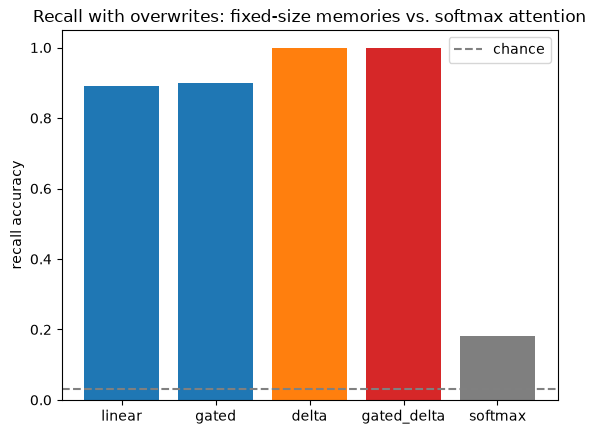

In [5]:
plt.bar(results.keys(), results.values(), color=["C0", "C0", "C1", "C3", "C7"])
plt.axhline(1 / NV, ls="--", c="gray", label="chance"); plt.ylabel("recall accuracy"); plt.legend()
plt.title("Recall with overwrites: fixed-size memories vs. softmax attention"); plt.show()

## Takeaways
- The delta rule turns the memory into an online least-squares learner: it **replaces** what is stored at a key instead of piling values on top. In the trained comparison above, the two delta variants make the fewest recall errors at the same state size.
- Softmax attention scores low here, but not because it can't do the task. With this short budget it is still on the loss plateau before it learns the key→value binding (notebook 75 shows the same plateau and how a local layer removes it). The recurrent memories get that binding almost for free from their short convolution. Toy budgets favour some inductive biases; real comparisons need long contexts and many more tokens, and the papers report the delta-rule advantage mostly on recall-heavy benchmarks at scale.
- Production models (Qwen3-Next, Kimi Linear) are **hybrids**: mostly linear-memory layers for cheap long contexts, plus a few full-attention layers for exact retrieval.